# DATA 266 - Homework 12: GPTQ Quantization and Knowledge Distillation

This homework looks at two ways to make a model smaller. The instructions say "HW11" in a few places, so the table names stay HW11.1 and HW11.2 to match.

- **Part 1: GPTQ.** Take a base LLM, quantize it to 4 bits, and see what that does to Wikitext-2 perplexity, p50/p95 latency, peak GPU memory and size on disk.
- **Part 2: Knowledge distillation.** Use the BERT teacher we were given (AG News) to train a smaller `distilbert-base-uncased` student. One sweep changes the temperature and another changes the loss weighting.

The two parts use different models and different tasks, so their accuracy numbers can't be compared and I keep them in separate tables.

The other files in the HW12 folder (smolagents, LangGraph, function calling, memory) are about agents, so they aren't used here.

**Why there's no GPTQ library:** the current `gptqmodel` package needs torch 2.15 or newer, and upgrading torch on Kaggle could break the CUDA setup. So the GPTQ algorithm (Frantar et al.) is written directly in PyTorch. The 4-bit weights are really packed, two per byte. The catch is that they get unpacked in Python on every forward pass, so **the latency here says something about this version, not about GPTQ in general**.

## 1. Personal Parameters

**SEED** is used for the calibration sample, the validation split, the data order and the student's new classification head. **SLICE** is where the latency texts start in the test sets. HP_ID, CLS_A and CLS_B are just reported, since the assignment says HP_ID doesn't add an extra temperature.

In [1]:
SID4 = 9486
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
assert (SEED, SLICE, HP_ID, CLS_A, CLS_B) == (9486, 486, 0, 6, 0)
for name in ["SID4", "SEED", "SLICE", "HP_ID", "CLS_A", "CLS_B"]:
    print(f"{name:5} = {globals()[name]}")

SID4  = 9486
SEED  = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0


## 2. Setup

Kaggle already has everything this needs. With `HW12_SMOKE_TEST=1` the notebook runs on tiny subsets, just to check that all the cells work. Those numbers don't mean anything.

In [2]:
import os, gc, json, glob, math, random, shutil, subprocess, sys, time, zipfile
from datetime import datetime, timezone

import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from transformers import (AutoConfig, AutoModelForCausalLM, AutoModelForSequenceClassification,
                          AutoTokenizer, get_linear_schedule_with_warmup)
from datasets import load_dataset
from safetensors.torch import load_model, save_model
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

transformers.logging.set_verbosity_error()
SMOKE_TEST = os.environ.get("HW12_SMOKE_TEST", "0") == "1"

# Part 1 (check the base model with the instructor's link before the real run)
LLM_ID = "facebook/opt-125m"
LLM_REVISION = "27dcfa74d334bc871f3234de431e71c6eeba5dd6"
BITS, GROUP, DAMP = 4, 128, 0.01
N_CALIB, CALIB_LEN, EVAL_LEN = 128, 512, 2048
PROMPT_LEN, NEW_TOKENS, N_LAT, N_WARM = 128, 64, 50, 5

# Part 2
TEACHER_DIR = os.environ.get("HW12_TEACHER_DIR", "")      # empty = search for it
STUDENT_ID = "distilbert/distilbert-base-uncased"
STUDENT_REVISION = "12040accade4e8a0f71eabdb258fecc2e7e948be"
MAX_LEN, BATCH, EPOCHS, LR, WARMUP = 128, 64, 2, 3e-5, 0.06
N_VAL = 6000
TEMPS, SWEEP_ALPHA, ALPHAS = [1, 2, 5, 10], 0.5, [0.25, 0.5, 0.75]
N_LAT_KD = 200
TRAIN_LIMIT = TEST_LIMIT = None

if SMOKE_TEST:
    N_CALIB, N_LAT, N_WARM, EPOCHS = 8, 5, 1, 1
    N_VAL, TRAIN_LIMIT, TEST_LIMIT, N_LAT_KD = 200, 1200, 800, 20

for d in ["figures", "results", "checkpoints"]:
    os.makedirs(d, exist_ok=True)
LOG_PATH = "results/run_log_raw.txt"
open(LOG_PATH, "w").close()

def log(*a):
    line = f"[{datetime.now(timezone.utc):%Y-%m-%dT%H:%M:%SZ}] " + " ".join(str(x) for x in a)
    print(line)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

assert torch.cuda.is_available(), "Turn on a GPU: Kaggle -> Settings -> Accelerator -> GPU T4 x2"
device = "cuda:0"          # only one of the two T4s is used, so both models see the same hardware
RUN_START = time.time()

def free():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9

def weight_mb(path):
    files = [path] if os.path.isfile(path) else glob.glob(os.path.join(path, "*.safetensors"))
    assert files, f"no safetensors weights in {path}"
    return sum(os.path.getsize(f) for f in files) / 1e6

set_seed()
log("GPU", torch.cuda.get_device_name(0), "| python", sys.version.split()[0], "| torch", torch.__version__,
    "| transformers", transformers.__version__, "| smoke test", SMOKE_TEST)

[2026-11-24T08:54:53Z] GPU Tesla T4 | python 3.13.16 | torch 2.11.0+cu130 | transformers 5.20.2 | smoke test False


# Part 1: GPTQ

## 3. Base Model and Wikitext-2

The model ID and revision are fixed in the settings so both configurations start from exactly the same model. Calibration uses random 512-token windows from the Wikitext-2 **train** split. Perplexity uses the whole **test** split, cut into windows of up to 2,048 tokens that don't overlap. Both models run in fp16 on the same GPU.

**Choice of model:** the GPTQ page linked in the assignment (the Hugging Face Transformers docs) doesn't require a particular base model. I used `facebook/opt-125m`, which is small enough to measure quickly on one T4. The exact ID and revision are recorded in the output below and in `results/hw12_metrics.json`. That page uses `GPTQConfig` with the `gptqmodel` library, and this notebook uses its own implementation instead (reason at the top).

In [3]:
def load_base():
    m = AutoModelForCausalLM.from_pretrained(LLM_ID, revision=LLM_REVISION)
    return m.half().to(device).eval()

tok_lm = AutoTokenizer.from_pretrained(LLM_ID, revision=LLM_REVISION)

def wiki_ids(split):
    ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)
    return tok_lm("\n\n".join(ds["text"]), return_tensors="pt")["input_ids"][0]

train_ids, test_ids = wiki_ids("train"), wiki_ids("test")
if SMOKE_TEST:
    test_ids = test_ids[:8192]
g = torch.Generator().manual_seed(SEED)
starts = torch.randint(0, len(train_ids) - CALIB_LEN, (N_CALIB,), generator=g).tolist()
calib = torch.stack([train_ids[s:s + CALIB_LEN] for s in starts])
prompt = test_ids[SLICE:SLICE + PROMPT_LEN].unsqueeze(0).to(device)
log(f"model {LLM_ID} @ {LLM_REVISION} | train tokens {len(train_ids):,} | test tokens {len(test_ids):,} | calibration {tuple(calib.shape)}")

config.json:   0%|          | 0.00/651 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/685 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/441 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

... (6 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[2026-11-24T08:55:13Z] model facebook/opt-125m @ 27dcfa74d334bc871f3234de431e71c6eeba5dd6 | train tokens 2,428,602 | test tokens 287,645 | calibration (128, 512)


## 4. Measurement Functions

Latency is the time for one full greedy `generate` call: 128 prompt tokens, exactly 64 new tokens, batch size 1. The warm-up runs aren't counted, and `cuda.synchronize()` is called before and after because GPU work is asynchronous. Peak memory is `max_memory_allocated` during those calls, with no other model on the GPU. The perplexity run has its own peak, which comes mostly from the big logits tensor.

In [4]:
@torch.inference_mode()
def perplexity(model):
    total, count = 0.0, 0
    for i in range(0, len(test_ids), EVAL_LEN):
        ids = test_ids[i:i + EVAL_LEN].unsqueeze(0).to(device)
        if ids.shape[1] < 2:
            continue
        logits = model(input_ids=ids, use_cache=False).logits[0, :-1].float()
        total += F.cross_entropy(logits, ids[0, 1:], reduction="sum").item()
        count += ids.shape[1] - 1
    loss = total / count
    return loss, math.exp(loss)

@torch.inference_mode()
def generation_latency(model):
    kw = dict(attention_mask=torch.ones_like(prompt), do_sample=False, max_new_tokens=NEW_TOKENS,
              min_new_tokens=NEW_TOKENS, pad_token_id=tok_lm.pad_token_id or tok_lm.eos_token_id)
    times = []
    for i in range(N_WARM + N_LAT):
        torch.cuda.synchronize(); t = time.perf_counter()
        out = model.generate(prompt, **kw)
        torch.cuda.synchronize()
        if i >= N_WARM:
            times.append(1000 * (time.perf_counter() - t))
    assert out.shape[1] == PROMPT_LEN + NEW_TOKENS
    return np.array(times), out[0, PROMPT_LEN:]

def measure_llm(model, name, size_mb):
    free()
    static = torch.cuda.memory_allocated() / 1e9
    times, gen = generation_latency(model)
    peak = peak_gb()
    free()
    loss, ppl = perplexity(model)
    row = {"Configuration": name, "Eval loss": loss, "Perplexity": ppl, "p50 ms": np.percentile(times, 50),
           "p95 ms": np.percentile(times, 95), "Peak memory GB": peak, "Size on disk MB": size_mb,
           "Loaded memory GB": static, "Perplexity-run peak GB": peak_gb()}
    log(name, {k: round(v, 4) for k, v in row.items() if k != "Configuration"})
    print("generated:", tok_lm.decode(gen)[:250])
    return row

model = load_base()
model.save_pretrained("checkpoints/base_llm")
base_row = measure_llm(model, "Base LLM (fp16)", weight_mb("checkpoints/base_llm"))

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  251MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  251MB            

model.safetensors: downloading bytes:           |  0.00B            

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T08:55:55Z] Base LLM (fp16) {'Eval loss': 3.32, 'Perplexity': 27.6615, 'p50 ms': np.float64(513.7007), 'p95 ms': np.float64(540.9138), 'Peak memory GB': 0.2762, 'Size on disk MB': 250.501, 'Loaded memory GB': 0.2574, 'Perplexity-run peak GB': 1.2968}
generated:  in the episode " The Long Firm " , and was a recurring character in the episode " The Long Firm " , and was a recurring character in the episode " The Long Firm " , and was a recurring character in the episode " The Long Firm " , and was a recurring


## 5. GPTQ Implementation

The simple way to quantize is to round each weight to the nearest level, but that treats every weight error as equally bad. GPTQ tries to keep the layer's **output** close to the original instead. For each linear layer it collects $H = \frac{2}{n}XX^T$ from the calibration inputs. Then it quantizes one column at a time and uses the inverse Hessian to adjust the columns that aren't quantized yet, so they make up for the error.

Settings: 4 bits, asymmetric, one scale and zero point per row and group of 128 columns, 1% damping. All the linear layers inside the decoder blocks are quantized. The embeddings and the tied output head stay in fp16. The blocks go in order, so later blocks see inputs from blocks that are already quantized.

As a sanity check, plain round-to-nearest (same grid, no Hessian) is run too. GPTQ should be clearly better, and if it isn't, something is wrong in the code.

In [5]:
QMAX = 2 ** BITS - 1

def decoder_layers(m):
    return m.model.decoder.layers if hasattr(m.model, "decoder") else m.model.layers

def grid(w):
    # asymmetric range per row; the range always contains 0
    lo, hi = w.amin(1).clamp(max=0), w.amax(1).clamp(min=0)
    scale = ((hi - lo) / QMAX).clamp(min=1e-5).half().float()      # stored as fp16, so quantize with the stored value
    zp = torch.round(-lo / scale).clamp(0, QMAX)
    return scale, zp

@torch.no_grad()
def quantize_weight(W, H=None):
    # H=None: round to nearest. Otherwise GPTQ. Returns codes, scales, zero points.
    W = W.float().clone()
    rows, cols = W.shape
    assert cols % GROUP == 0, f"{cols} inputs is not a multiple of the group size"
    codes = torch.zeros(rows, cols, dtype=torch.uint8, device=W.device)
    scales, zps, U = [], [], None
    if H is not None:
        H = H.clone()
        dead = torch.diag(H) == 0
        H[dead, dead] = 1
        W[:, dead] = 0
        idx = torch.arange(cols, device=W.device)
        damp = DAMP * torch.diag(H).mean()
        for _ in range(6):                                          # more damping if H is not positive definite
            H[idx, idx] += damp
            try:
                Hinv = torch.cholesky_inverse(torch.linalg.cholesky(H))
                U = torch.linalg.cholesky((Hinv + Hinv.T) / 2, upper=True)
                break
            except torch.linalg.LinAlgError:
                damp *= 10
        assert U is not None, "Cholesky failed even with extra damping"
    for a in range(0, cols, GROUP):
        b = a + GROUP
        W1 = W[:, a:b].clone()
        scale, zp = grid(W1)
        scales.append(scale); zps.append(zp)
        if U is None:
            codes[:, a:b] = (torch.round(W1 / scale[:, None]) + zp[:, None]).clamp(0, QMAX).to(torch.uint8)
            continue
        U1, E = U[a:b, a:b], torch.zeros_like(W1)
        for i in range(GROUP):
            w = W1[:, i]
            q = (torch.round(w / scale) + zp).clamp(0, QMAX)
            codes[:, a + i] = q.to(torch.uint8)
            err = (w - (q - zp) * scale) / U1[i, i]
            E[:, i] = err
            W1[:, i:] -= torch.outer(err, U1[i, i:])
        W[:, b:] -= E @ U[a:b, b:]
    return codes, torch.stack(scales, 1), torch.stack(zps, 1)

class Linear4bit(nn.Module):
    def __init__(self, in_features, out_features, bias):
        super().__init__()
        self.in_features, self.out_features = in_features, out_features
        n = in_features // GROUP
        self.register_buffer("packed", torch.zeros(out_features, in_features // 2, dtype=torch.uint8))
        self.register_buffer("scale", torch.zeros(out_features, n, dtype=torch.float16))
        self.register_buffer("zp", torch.zeros(out_features, n, dtype=torch.uint8))
        self.register_buffer("bias", torch.zeros(out_features, dtype=torch.float16) if bias else None)

    @classmethod
    def from_codes(cls, lin, codes, scale, zp):
        m = cls(lin.in_features, lin.out_features, lin.bias is not None).to(codes.device)
        m.packed.copy_(codes[:, 0::2] | (codes[:, 1::2] << 4))      # two 4-bit codes per byte
        m.scale.copy_(scale); m.zp.copy_(zp)
        if lin.bias is not None:
            m.bias.copy_(lin.bias)
        return m

    def codes(self):
        return torch.stack([self.packed & 15, self.packed >> 4], dim=-1).flatten(1)

    def weight_fp(self, dtype):
        c = self.codes().view(self.out_features, -1, GROUP).to(dtype)
        return ((c - self.zp.to(dtype)[..., None]) * self.scale.to(dtype)[..., None]).flatten(1)

    def forward(self, x):
        return F.linear(x, self.weight_fp(x.dtype), None if self.bias is None else self.bias.to(x.dtype))

def set_module(root, name, new):
    parent, _, leaf = name.rpartition(".")
    setattr(root.get_submodule(parent) if parent else root, leaf, new)

# packing check on random codes
_lin = nn.Linear(2 * GROUP, 4)
_c = torch.randint(0, 16, (4, 2 * GROUP), dtype=torch.uint8)
assert torch.equal(Linear4bit.from_codes(_lin, _c, torch.ones(4, 2), torch.zeros(4, 2)).codes(), _c)
print("4-bit pack/unpack check passed")

4-bit pack/unpack check passed


In [6]:
@torch.no_grad()
def quantize_model(m, method):
    layers = decoder_layers(m)
    for li, block in enumerate(tqdm(layers, desc=method)):
        linears = {n: x for n, x in block.named_modules() if isinstance(x, nn.Linear)}
        H, seen = {}, {}
        if method == "gptq":
            hooks = []
            def make_hook(name):
                def hook(mod, inp, out):
                    x = inp[0].detach().reshape(-1, mod.in_features).float()
                    n = x.shape[0]
                    if name not in H:
                        H[name] = torch.zeros(mod.in_features, mod.in_features, device=x.device); seen[name] = 0
                    H[name] *= seen[name] / (seen[name] + n)
                    seen[name] += n
                    x = math.sqrt(2 / seen[name]) * x
                    H[name] += x.T @ x
                return hook
            for n, x in linears.items():
                hooks.append(x.register_forward_hook(make_hook(n)))
            # simple but not the fastest: a full forward pass per block, so it doesn't depend on model internals
            for i in range(0, N_CALIB, 8):
                m(input_ids=calib[i:i + 8].to(device), use_cache=False, logits_to_keep=1) if "logits_to_keep" in FWD_ARGS \
                    else m(input_ids=calib[i:i + 8].to(device), use_cache=False)
            for h in hooks:
                h.remove()
            assert set(H) == set(linears), "some linear layers got no calibration data"
        for n, lin in linears.items():
            set_module(block, n, Linear4bit.from_codes(lin, *quantize_weight(lin.weight.data, H.get(n))))
    return m

import inspect
FWD_ARGS = inspect.signature(model.forward).parameters

# check: round to nearest on the same grid
rtn_loss, rtn_ppl = perplexity(quantize_model(model, "rtn"))
log(f"round-to-nearest 4-bit check: loss {rtn_loss:.4f} | perplexity {rtn_ppl:.3f}")
del model; free()

model = load_base()
t0 = time.time()
quantize_model(model, "gptq")
gptq_seconds = time.time() - t0
free()
pre_loss, pre_ppl = perplexity(model)
save_model(model, "checkpoints/gptq_llm.safetensors")
log(f"GPTQ took {gptq_seconds:.1f}s | perplexity before saving {pre_ppl:.3f}")
del model; free()

rtn:   0%|          | 0/12 [00:00<?, ?it/s]

[2026-11-24T08:56:02Z] round-to-nearest 4-bit check: loss 3.4177 | perplexity 30.499


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

gptq:   0%|          | 0/12 [00:00<?, ?it/s]

[2026-11-24T08:56:40Z] GPTQ took 30.1s | perplexity before saving 29.718


## 6. Reload the Quantized Model and Compare

Before measuring, the quantized model is rebuilt from the saved file. This makes sure the file has everything it needs and that the base model isn't still sitting on the GPU. The sizes only count the weight files: fp16 for the base model, and 4-bit plus the fp16 parts for the quantized one.

In [7]:
def load_quantized(path):
    m = AutoModelForCausalLM.from_config(AutoConfig.from_pretrained(LLM_ID, revision=LLM_REVISION)).half()
    for block in decoder_layers(m):
        for n, lin in [(n, x) for n, x in block.named_modules() if isinstance(x, nn.Linear)]:
            set_module(block, n, Linear4bit(lin.in_features, lin.out_features, lin.bias is not None))
    m.tie_weights()
    load_model(m, path)
    return m.to(device).eval()

model = load_quantized("checkpoints/gptq_llm.safetensors")
gptq_row = measure_llm(model, "GPTQ-quantized LLM (4-bit)", weight_mb("checkpoints/gptq_llm.safetensors"))
assert abs(gptq_row["Eval loss"] - pre_loss) < 0.01, "reloaded model differs from the model that was saved"
del model; free()

llm = pd.DataFrame([base_row, gptq_row])
t1 = pd.DataFrame({"Configuration": llm["Configuration"],
                   "Quality metric (perplexity / eval loss)": [f"{a:.3f} / {b:.4f}" for a, b in zip(llm["Perplexity"], llm["Eval loss"])],
                   "p50 / p95 latency (ms)": [f"{a:.1f} / {b:.1f}" for a, b in zip(llm["p50 ms"], llm["p95 ms"])],
                   "Peak memory (GB)": llm["Peak memory GB"].round(3), "Size on disk (MB)": llm["Size on disk MB"].round(1)})
print("Table HW11.1 - GPTQ comparison on the same LLM/task\n")
print(t1.to_string(index=False))
print(f"\nround-to-nearest check perplexity: {rtn_ppl:.3f}")
if gptq_row["Perplexity"] >= rtn_ppl:
    log("WARNING: GPTQ is not better than round-to-nearest, check the implementation before using these numbers")
llm.to_csv("results/part1_gptq.csv", index=False)

[2026-11-24T08:58:07Z] GPTQ-quantized LLM (4-bit) {'Eval loss': 3.3918, 'Perplexity': 29.7181, 'p50 ms': np.float64(1257.6306), 'p95 ms': np.float64(1296.6164), 'Peak memory GB': 0.1586, 'Size on disk MB': 125.1052, 'Loaded memory GB': 0.137, 'Perplexity-run peak GB': 1.1662}
generated:  in the episode " The Long Firm " , and was a recurring character in the episode " The Long Firm " , and was a recurring character in the episode " The Long Firm " , and was a recurring character in the episode " The Long Firm " , and was a recurring
Table HW11.1 - GPTQ comparison on the same LLM/task

             Configuration Quality metric (perplexity / eval loss) p50 / p95 latency (ms)  Peak memory (GB)  Size on disk (MB)
           Base LLM (fp16)                         27.661 / 3.3200          513.7 / 540.9             0.276              250.5
GPTQ-quantized LLM (4-bit)                         29.718 / 3.3918        1257.6 / 1296.6             0.159              125.1

round-to-nearest check per

## 7. Findings for Part 1

**Table HW11.1: GPTQ comparison on the same LLM/task** (`facebook/opt-125m`, one Tesla T4)

| Configuration | Quality metric (perplexity / eval loss) | p50 / p95 latency (ms) | Peak memory (GB) | Size on disk (MB) |
| --- | ---: | ---: | ---: | ---: |
| Base LLM (fp16) | 27.66 / 3.3200 | 513.7 / 540.9 | 0.276 | 250.5 |
| GPTQ-quantized LLM (4-bit) | 29.72 / 3.3918 | 1257.6 / 1296.6 | 0.159 | 125.1 |

- **Quality:** perplexity went up from 27.66 to 29.72 (+7.4%), so the model got a little worse, but it's still usable. Plain round-to-nearest with the same 4-bit grid got 30.50, so GPTQ made back about 28% of the perplexity that simple rounding lost. This is what the sanity check was supposed to show. The perplexity after reloading (29.718) is the same as before saving.
- **Size:** the file is half as big (250.5 → 125.1 MB), not a quarter. The embeddings (about 80 MB in fp16) aren't quantized. Without them, the rest shrinks from about 170 to 45 MB, which is close to 4×. The missing part is mainly the scales and zero points.
- **Memory:** the peak during generation dropped by 43% (0.276 → 0.159 GB). During the perplexity run it only dropped by 10% (1.297 → 1.166 GB), because there the big logits tensor takes most of the memory and quantization doesn't change that.
- **Speed:** the quantized model is **2.4× slower** (p50 514 → 1258 ms). This comes from my implementation, which unpacks the 4-bit weights in Python for every layer on every forward pass. A library with real 4-bit GPU kernels should do better, but I didn't measure one, so I can't say how much.

Both models wrote the same repetitive text for the test prompt, so for this prompt quantization didn't change the output. It's only one prompt, so it doesn't prove much.

# Part 2: Knowledge Distillation

## 8. Load the Teacher

The teacher is the `teacher_model.7z` we were given, uploaded as a Kaggle dataset. If Kaggle already unpacked it, the cell uses that folder. If not, it extracts the archive to `/tmp` with a system tool, or with `py7zr` if there isn't one. If no teacher is found it stops, because a different teacher would change the assignment. It also checks that the teacher's labels are in the same order as the AG News labels.

In [8]:
EXTRACT_DIR = "/tmp/hw12_teacher"

def extract_teacher():
    # returns True if an archive was found and extracted
    archives = sorted(p for root in ["/kaggle/input", "."]
                      for p in glob.glob(os.path.join(root, "**", "teacher_model*.7z"), recursive=True) if os.path.isfile(p))
    if not archives:
        return False
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    log("extracting", os.path.basename(archives[0]))
    tool = next((t for t in ["7z", "7za", "7zz", "bsdtar"] if shutil.which(t)), None)
    if tool == "bsdtar":
        subprocess.check_call([tool, "-xf", archives[0], "-C", EXTRACT_DIR])
    elif tool:
        subprocess.check_call([tool, "x", "-y", f"-o{EXTRACT_DIR}", archives[0]], stdout=subprocess.DEVNULL)
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "py7zr"])
        import py7zr
        with py7zr.SevenZipFile(archives[0]) as z:
            z.extractall(EXTRACT_DIR)
    return True

def find_teacher():
    if TEACHER_DIR:
        return TEACHER_DIR
    found = search_teacher(["/kaggle/input", "."])
    if not found and extract_teacher():
        found = search_teacher([EXTRACT_DIR])
    if len(found) != 1:
        raise FileNotFoundError(f"expected one BERT teacher folder, found {found}. Attach the Kaggle dataset with "
                                "teacher_model.7z, or set TEACHER_DIR in the settings cell.")
    return found[0]

def search_teacher(roots):
    found = []
    for root in roots:
        for p in glob.glob(os.path.join(root, "**", "config.json"), recursive=True):
            try:
                kind = json.load(open(p)).get("model_type")
            except (OSError, ValueError, AttributeError):
                continue
            if kind == "bert" and "checkpoints" not in os.path.relpath(p, root).split(os.sep):
                found.append(os.path.dirname(p))
    return [f for f in found if "teacher" in f.lower()] or found

TEACHER_DIR = find_teacher()
tok_t = AutoTokenizer.from_pretrained(TEACHER_DIR)
tok_s = AutoTokenizer.from_pretrained(STUDENT_ID, revision=STUDENT_REVISION)

def load_teacher():
    return AutoModelForSequenceClassification.from_pretrained(TEACHER_DIR).float().to(device).eval()

teacher = load_teacher()
assert teacher.config.num_labels == 4, teacher.config.num_labels
log("teacher:", os.path.basename(TEACHER_DIR), "|", teacher.config.num_hidden_layers, "layers |",
    f"{sum(p.numel() for p in teacher.parameters()):,} parameters | id2label", teacher.config.id2label)

ag_train = load_dataset("fancyzhx/ag_news", split="train")
ag_test = load_dataset("fancyzhx/ag_news", split="test")
if SMOKE_TEST:
    ag_train = ag_train.shuffle(seed=SEED).select(range(TRAIN_LIMIT))
    ag_test = ag_test.shuffle(seed=SEED).select(range(TEST_LIMIT))
CLASSES = ag_test.features["label"].names
y_train, y_test = np.array(ag_train["label"]), np.array(ag_test["label"])
train_text, test_text = list(ag_train["text"]), list(ag_test["text"])

def encode(tok, texts):
    return tok(texts, truncation=True, max_length=MAX_LEN)["input_ids"]

enc = {("t", "train"): encode(tok_t, train_text), ("t", "test"): encode(tok_t, test_text),
       ("s", "train"): encode(tok_s, train_text), ("s", "test"): encode(tok_s, test_text)}
log(f"AG News: {len(y_train):,} train, {len(y_test):,} test | classes {CLASSES}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[2026-11-24T08:59:51Z] teacher: teacher_model | 12 layers | 109,485,316 parameters | id2label {0: 'WORLD', 1: 'SPORTS', 2: 'BUSINESS', 3: 'SCI/TECH'}


... (4 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

[2026-11-24T09:00:22Z] AG News: 120,000 train, 7,600 test | classes ['World', 'Sports', 'Business', 'Sci/Tech']


## 9. Teacher Logits for All Training Samples

The teacher and student each use their own tokenizer. The teacher logits are saved by sample index, so each student batch can look them up and the teacher only has to run once. I also hold out 6,000 training samples as a **validation set** for picking the best temperature and α. Picking them on the test set would make the final test accuracy look better than it should.

In [9]:
def collate(seqs, pad_id):
    n = max(len(s) for s in seqs)
    ids = torch.full((len(seqs), n), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), n), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s); mask[i, :len(s)] = 1
    return ids.to(device), mask.to(device)

@torch.no_grad()      # not inference_mode: the teacher logits are used in the training loss later
def predict_logits(model, seqs, pad_id, bs=128, amp=True):
    order = np.argsort([len(s) for s in seqs], kind="stable")
    out = torch.zeros(len(seqs), 4)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        ids, mask = collate([seqs[j] for j in idx], pad_id)
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            z = model(input_ids=ids, attention_mask=mask).logits
        out[torch.as_tensor(idx)] = z.float().cpu()
    return out

t0 = time.time()
teacher_train = predict_logits(teacher, enc["t", "train"], tok_t.pad_token_id)
assert torch.isfinite(teacher_train).all() and teacher_train.shape == (len(y_train), 4)
log(f"teacher logits for {len(y_train):,} training samples in {time.time() - t0:.1f}s")
teacher_test = predict_logits(teacher, enc["t", "test"], tok_t.pad_token_id, amp=False)
teacher_pred = teacher_test.argmax(1).numpy()
teacher_acc = (teacher_pred == y_test).mean()
train_acc_t = (teacher_train.argmax(1).numpy() == y_train).mean()
log(f"teacher accuracy: train {train_acc_t:.4f} | test {teacher_acc:.4f}")
assert teacher_acc > 0.85, "teacher accuracy is too low: check label order, tokenizer or folder"
torch.save(teacher_train, "checkpoints/teacher_train_logits.pt")
del teacher; free()

perm = np.random.default_rng(SEED).permutation(len(y_train))
val_idx, fit_idx = perm[:N_VAL], perm[N_VAL:]
enc_val = [enc["s", "train"][i] for i in val_idx]

[2026-11-24T09:01:39Z] teacher logits for 120,000 training samples in 77.5s
[2026-11-24T09:02:00Z] teacher accuracy: train 0.9895 | test 0.9443


## 10. Distillation Loss and Training

$$loss = \alpha \cdot CE(student, labels) + (1-\alpha) \cdot KLD, \qquad KLD = T^2 \cdot KL\big(softmax(z_t/T)\,\|\,softmax(z_s/T)\big)$$

The $T^2$ comes from Hinton et al. A higher temperature shrinks the gradients by about $1/T^2$, so multiplying by $T^2$ keeps the two parts of the loss on a similar scale. At T = 1 it changes nothing.

Every run starts over from the same pretrained DistilBERT checkpoint with the same SEED, so the new classification head and the batch order are the same too. The only thing that changes is T or α. Everything else is fixed: 2 epochs, batch 64, AdamW (lr 3e-5, weight decay 0.01), linear schedule with 6% warm-up, gradient clipping at 1, mixed precision.

In [10]:
def kd_loss(zs, zt, y, T, alpha):
    zs = zs.float()
    ce = F.cross_entropy(zs, y)
    kld = F.kl_div(F.log_softmax(zs / T, -1), F.softmax(zt / T, -1), reduction="batchmean") * T ** 2
    return alpha * ce + (1 - alpha) * kld, ce, kld

# check: identical logits give KLD = 0, and alpha = 1 is plain cross-entropy
_z, _y = torch.randn(8, 4), torch.randint(0, 4, (8,))
assert abs(kd_loss(_z, _z, _y, 5, 0.5)[2].item()) < 1e-5
assert torch.isclose(kd_loss(_z, -_z, _y, 5, 1.0)[0], F.cross_entropy(_z, _y))

def make_batches(rng):
    # shuffled batches of similar length, so there is little padding
    p = rng.permutation(fit_idx)
    out = []
    for i in range(0, len(p), BATCH * 50):
        chunk = sorted(p[i:i + BATCH * 50], key=lambda j: len(enc["s", "train"][j]))
        out += [np.array(chunk[k:k + BATCH]) for k in range(0, len(chunk), BATCH)]
    return [out[i] for i in rng.permutation(len(out))]

def load_student(path=None):
    if path:
        return AutoModelForSequenceClassification.from_pretrained(path).float().to(device)
    return AutoModelForSequenceClassification.from_pretrained(STUDENT_ID, revision=STUDENT_REVISION, num_labels=4).float().to(device)

def train_student(name, T, alpha):
    set_seed()                                   # same head initialization, dropout seed and batch order in every run
    rng = np.random.default_rng(SEED)
    student = load_student()
    opt = torch.optim.AdamW(student.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS * math.ceil(len(fit_idx) / BATCH)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP * steps), steps)
    scaler = torch.amp.GradScaler("cuda")
    history, window, step, t0 = [], [], 0, time.time()
    log(f"=== {name}: T={T}, alpha={alpha}, {steps} steps")
    for ep in range(EPOCHS):
        student.train()
        for idx in make_batches(rng):
            ids, mask = collate([enc["s", "train"][j] for j in idx], tok_s.pad_token_id)
            y = torch.as_tensor(y_train[idx]).to(device)
            zt = teacher_train[torch.as_tensor(idx)].to(device)
            with torch.autocast("cuda", dtype=torch.float16):
                zs = student(input_ids=ids, attention_mask=mask).logits
            loss, ce, kld = kd_loss(zs, zt, y, T, alpha)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(student.parameters(), 1.0)
            before = scaler.get_scale()
            scaler.step(opt); scaler.update()
            if scaler.get_scale() >= before:     # no scheduler step if the optimizer step was skipped
                sched.step()
            step += 1
            window.append(torch.stack([loss.detach(), ce.detach(), kld.detach()]))
            if step % 100 == 0 or step == steps:
                m = torch.stack(window).mean(0).tolist(); window = []
                history.append({"step": step, "loss": m[0], "ce": m[1], "kld": m[2]})
                if step % 500 == 0 or step == steps:
                    log(f"{name} step {step}/{steps} loss {m[0]:.4f} ce {m[1]:.4f} kld {m[2]:.4f}")
        student.eval()
        val_acc = (predict_logits(student, enc_val, tok_s.pad_token_id).argmax(1).numpy() == y_train[val_idx]).mean()
        log(f"{name} epoch {ep + 1}/{EPOCHS}: val accuracy {val_acc:.4f} | {time.time() - t0:.0f}s")
    test_pred = predict_logits(student, enc["s", "test"], tok_s.pad_token_id, amp=False).argmax(1).numpy()
    res = {"name": name, "T": T, "alpha": alpha, "val_acc": float(val_acc), "test_acc": float((test_pred == y_test).mean()),
           "final_loss": history[-1]["loss"], "final_ce": history[-1]["ce"], "final_kld": history[-1]["kld"],
           "seconds": time.time() - t0}
    student.save_pretrained(f"checkpoints/{name}")
    pd.DataFrame(history).to_csv(f"results/loss_{name}.csv", index=False)
    log(f"{name} done: val {res['val_acc']:.4f} | test {res['test_acc']:.4f} | {res['seconds']:.0f}s")
    del student, opt; free()
    return res, history

def keep_only(names):
    for r in RES:
        if r not in names:
            shutil.rmtree(f"checkpoints/{r}", ignore_errors=True)

RES, HIST = {}, {}

## 11. Temperature Sweep (α = 0.5)

The best T is the one with the highest validation accuracy. If there's a tie, the lower T wins.

In [11]:
for T in TEMPS:
    name = f"T{T}_a{SWEEP_ALPHA}"
    RES[name], HIST[name] = train_student(name, T, SWEEP_ALPHA)
    log(f"rough time left for the remaining runs: {(len(TEMPS) + len(ALPHAS) - len(RES)) * RES[name]['seconds'] / 60:.0f} min")

sweep_T = pd.DataFrame([RES[f"T{T}_a{SWEEP_ALPHA}"] for T in TEMPS])
best_T = max(TEMPS, key=lambda T: (RES[f"T{T}_a{SWEEP_ALPHA}"]["val_acc"], -T))
print(sweep_T.drop(columns="name").round(4).to_string(index=False))
log("best temperature (validation):", best_T)
keep_only([f"T{best_T}_a{SWEEP_ALPHA}"])

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[2026-11-24T09:02:03Z] === T1_a0.5: T=1, alpha=0.5, 3564 steps
[2026-11-24T09:02:50Z] T1_a0.5 step 500/3564 loss 0.2209 ce 0.2348 kld 0.2069
[2026-11-24T09:03:36Z] T1_a0.5 step 1000/3564 loss 0.1825 ce 0.2001 kld 0.1648
[2026-11-24T09:04:22Z] T1_a0.5 step 1500/3564 loss 0.1526 ce 0.1704 kld 0.1347
[2026-11-24T09:04:50Z] T1_a0.5 epoch 1/2: val accuracy 0.9393 | 167s
[2026-11-24T09:05:10Z] T1_a0.5 step 2000/3564 loss 0.1201 ce 0.1359 kld 0.1043
[2026-11-24T09:05:56Z] T1_a0.5 step 2500/3564 loss 0.1237 ce 0.1386 kld 0.1089
[2026-11-24T09:06:42Z] T1_a0.5 step 3000/3564 loss 0.1145 ce 0.1335 kld 0.0955
[2026-11-24T09:07:28Z] T1_a0.5 step 3500/3564 loss 0.1141 ce 0.1335 kld 0.0947
[2026-11-24T09:07:34Z] T1_a0.5 step 3564/3564 loss 0.1084 ce 0.1228 kld 0.0939
[2026-11-24T09:07:36Z] T1_a0.5 epoch 2/2: val accuracy 0.9428 | 332s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T09:07:47Z] T1_a0.5 done: val 0.9428 | test 0.9446 | 343s
[2026-11-24T09:07:47Z] rough time left for the remaining runs: 34 min


... (8 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[2026-11-24T09:19:15Z] === T10_a0.5: T=10, alpha=0.5, 3564 steps
[2026-11-24T09:20:01Z] T10_a0.5 step 500/3564 loss 0.7123 ce 0.3459 kld 1.0788
[2026-11-24T09:20:47Z] T10_a0.5 step 1000/3564 loss 0.4918 ce 0.2596 kld 0.7240
[2026-11-24T09:21:33Z] T10_a0.5 step 1500/3564 loss 0.3980 ce 0.2188 kld 0.5772
[2026-11-24T09:22:01Z] T10_a0.5 epoch 1/2: val accuracy 0.9372 | 166s
[2026-11-24T09:22:21Z] T10_a0.5 step 2000/3564 loss 0.3080 ce 0.1683 kld 0.4476
[2026-11-24T09:23:08Z] T10_a0.5 step 2500/3564 loss 0.3162 ce 0.1809 kld 0.4516
[2026-11-24T09:23:53Z] T10_a0.5 step 3000/3564 loss 0.2988 ce 0.1796 kld 0.4179
[2026-11-24T09:24:39Z] T10_a0.5 step 3500/3564 loss 0.2865 ce 0.1766 kld 0.3963
[2026-11-24T09:24:45Z] T10_a0.5 step 3564/3564 loss 0.2784 ce 0.1645 kld 0.3922
[2026-11-24T09:24:47Z] T10_a0.5 epoch 2/2: val accuracy 0.9432 | 332s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T09:24:58Z] T10_a0.5 done: val 0.9432 | test 0.9430 | 343s
[2026-11-24T09:24:59Z] rough time left for the remaining runs: 17 min
 T  alpha  val_acc  test_acc  final_loss  final_ce  final_kld  seconds
 1    0.5   0.9428    0.9446      0.1084    0.1228     0.0939 342.9275
 2    0.5   0.9428    0.9446      0.1987    0.1452     0.2522 342.3428
 5    0.5   0.9418    0.9436      0.2830    0.1636     0.4024 342.7530
10    0.5   0.9432    0.9430      0.2784    0.1645     0.3922 342.6413
[2026-11-24T09:24:59Z] best temperature (validation): 10


## 12. Loss-Weighting Sweep (best T)

This trains three new students at the best T. The α = 0.5 one is the same setup as the best run in the first sweep, but it's trained again because the assignment asks for three fresh students. It's also useful, because the gap between the two shows whether the training is reproducible with the same seed.

In [12]:
for a in ALPHAS:
    name = f"alpha{a}_T{best_T}"
    RES[name], HIST[name] = train_student(name, best_T, a)

sweep_A = pd.DataFrame([RES[f"alpha{a}_T{best_T}"] for a in ALPHAS])
print(sweep_A.drop(columns="name").round(4).to_string(index=False))
first = RES[f"T{best_T}_a{SWEEP_ALPHA}"]; again = RES[f"alpha{SWEEP_ALPHA}_T{best_T}"]
print(f"\nsame settings twice: test {first['test_acc']:.4f} vs {again['test_acc']:.4f}")
best_alpha = max(ALPHAS, key=lambda a: RES[f"alpha{a}_T{best_T}"]["val_acc"])
BEST = f"alpha{best_alpha}_T{best_T}"
log("best student (validation, loss-weighting sweep):", BEST)
keep_only([BEST])
pd.DataFrame(list(RES.values())).to_csv("results/part2_all_runs.csv", index=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[2026-11-24T09:24:59Z] === alpha0.25_T10: T=10, alpha=0.25, 3564 steps
[2026-11-24T09:25:45Z] alpha0.25_T10 step 500/3564 loss 0.8940 ce 0.3628 kld 1.0710
[2026-11-24T09:26:31Z] alpha0.25_T10 step 1000/3564 loss 0.6009 ce 0.2689 kld 0.7116
[2026-11-24T09:27:17Z] alpha0.25_T10 step 1500/3564 loss 0.4949 ce 0.2326 kld 0.5823
[2026-11-24T09:27:45Z] alpha0.25_T10 epoch 1/2: val accuracy 0.9348 | 166s
[2026-11-24T09:28:05Z] alpha0.25_T10 step 2000/3564 loss 0.3796 ce 0.1777 kld 0.4469
[2026-11-24T09:28:51Z] alpha0.25_T10 step 2500/3564 loss 0.3829 ce 0.1914 kld 0.4468
[2026-11-24T09:29:37Z] alpha0.25_T10 step 3000/3564 loss 0.3618 ce 0.1921 kld 0.4184
[2026-11-24T09:30:23Z] alpha0.25_T10 step 3500/3564 loss 0.3423 ce 0.1840 kld 0.3951
[2026-11-24T09:30:29Z] alpha0.25_T10 step 3564/3564 loss 0.3394 ce 0.1759 kld 0.3940
[2026-11-24T09:30:31Z] alpha0.25_T10 epoch 2/2: val accuracy 0.9435 | 332s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T09:30:42Z] alpha0.25_T10 done: val 0.9435 | test 0.9430 | 343s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[2026-11-24T09:30:43Z] === alpha0.5_T10: T=10, alpha=0.5, 3564 steps
[2026-11-24T09:31:29Z] alpha0.5_T10 step 500/3564 loss 0.7123 ce 0.3459 kld 1.0788
[2026-11-24T09:32:15Z] alpha0.5_T10 step 1000/3564 loss 0.4918 ce 0.2596 kld 0.7240
[2026-11-24T09:33:01Z] alpha0.5_T10 step 1500/3564 loss 0.3980 ce 0.2188 kld 0.5772
[2026-11-24T09:33:29Z] alpha0.5_T10 epoch 1/2: val accuracy 0.9372 | 166s
[2026-11-24T09:33:49Z] alpha0.5_T10 step 2000/3564 loss 0.3080 ce 0.1683 kld 0.4476
[2026-11-24T09:34:35Z] alpha0.5_T10 step 2500/3564 loss 0.3162 ce 0.1809 kld 0.4516
[2026-11-24T09:35:21Z] alpha0.5_T10 step 3000/3564 loss 0.2988 ce 0.1796 kld 0.4179
[2026-11-24T09:36:07Z] alpha0.5_T10 step 3500/3564 loss 0.2865 ce 0.1766 kld 0.3963
[2026-11-24T09:36:13Z] alpha0.5_T10 step 3564/3564 loss 0.2784 ce 0.1645 kld 0.3922
[2026-11-24T09:36:15Z] alpha0.5_T10 epoch 2/2: val accuracy 0.9432 | 332s


... (2 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[2026-11-24T09:36:27Z] === alpha0.75_T10: T=10, alpha=0.75, 3564 steps
[2026-11-24T09:37:13Z] alpha0.75_T10 step 500/3564 loss 0.4857 ce 0.2956 kld 1.0562
[2026-11-24T09:37:59Z] alpha0.75_T10 step 1000/3564 loss 0.3683 ce 0.2395 kld 0.7546
[2026-11-24T09:38:45Z] alpha0.75_T10 step 1500/3564 loss 0.3090 ce 0.2074 kld 0.6139
[2026-11-24T09:39:12Z] alpha0.75_T10 epoch 1/2: val accuracy 0.9365 | 166s
[2026-11-24T09:39:32Z] alpha0.75_T10 step 2000/3564 loss 0.2392 ce 0.1587 kld 0.4809
[2026-11-24T09:40:19Z] alpha0.75_T10 step 2500/3564 loss 0.2454 ce 0.1677 kld 0.4785
[2026-11-24T09:41:04Z] alpha0.75_T10 step 3000/3564 loss 0.2266 ce 0.1599 kld 0.4264
[2026-11-24T09:41:50Z] alpha0.75_T10 step 3500/3564 loss 0.2258 ce 0.1618 kld 0.4178
[2026-11-24T09:41:56Z] alpha0.75_T10 step 3564/3564 loss 0.2141 ce 0.1509 kld 0.4037
[2026-11-24T09:41:58Z] alpha0.75_T10 epoch 2/2: val accuracy 0.9430 | 332s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T09:42:09Z] alpha0.75_T10 done: val 0.9430 | test 0.9441 | 342s
 T  alpha  val_acc  test_acc  final_loss  final_ce  final_kld  seconds
10   0.25   0.9435    0.9430      0.3394    0.1759     0.3940 342.5320
10   0.50   0.9432    0.9430      0.2784    0.1645     0.3922 342.6704
10   0.75   0.9430    0.9441      0.2141    0.1509     0.4037 342.3702

same settings twice: test 0.9430 vs 0.9430
[2026-11-24T09:42:10Z] best student (validation, loss-weighting sweep): alpha0.25_T10


### Loss trends

The total losses for different T or α aren't on the same scale, so a lower total loss doesn't mean a better student. That's why the CE and KLD curves are plotted separately.

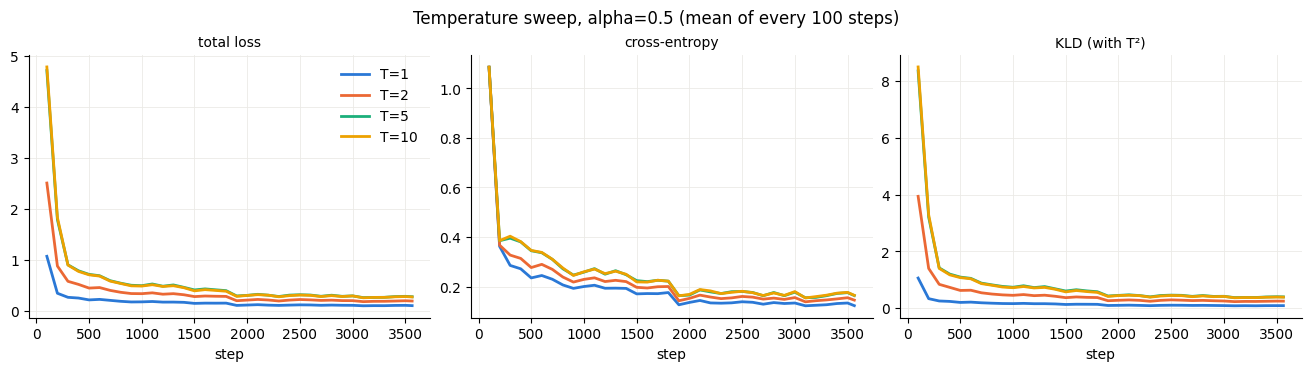

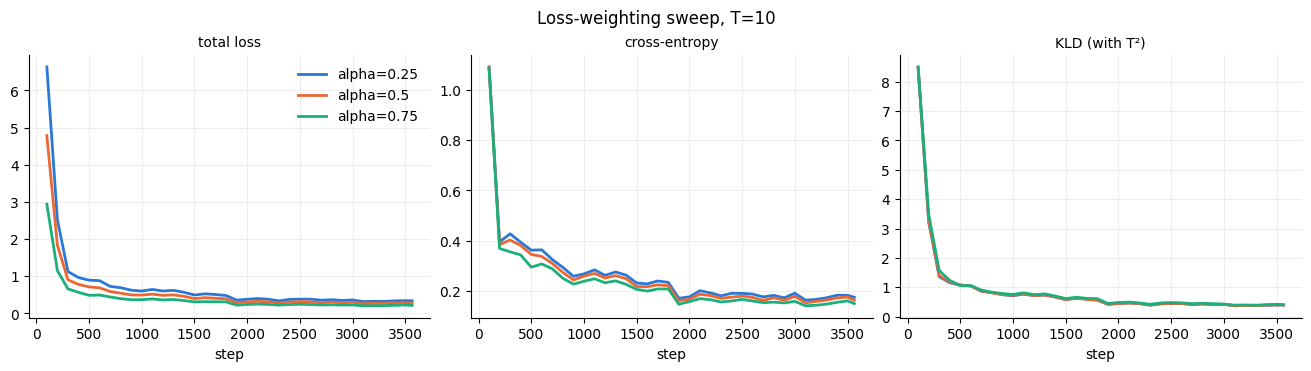

In [13]:
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
def loss_figure(names, labels, title, path):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
    for ax, key, lab in zip(axes, ["loss", "ce", "kld"], ["total loss", "cross-entropy", "KLD (with T²)"]):
        for n, l, c in zip(names, labels, COL):
            h = pd.DataFrame(HIST[n]); ax.plot(h.step, h[key], color=c, lw=2, label=l)
        ax.set_title(lab, fontsize=10); ax.set_xlabel("step"); ax.grid(color="#ebeae6", lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False); fig.suptitle(title)
    plt.savefig(path, dpi=130); plt.show()

loss_figure([f"T{T}_a{SWEEP_ALPHA}" for T in TEMPS], [f"T={T}" for T in TEMPS],
            f"Temperature sweep, alpha={SWEEP_ALPHA} (mean of every 100 steps)", "figures/loss_temperature_sweep.png")
loss_figure([f"alpha{a}_T{best_T}" for a in ALPHAS], [f"alpha={a}" for a in ALPHAS],
            f"Loss-weighting sweep, T={best_T}", "figures/loss_alpha_sweep.png")

## 13. Teacher vs. Best Student on the AG News Test Set

Both models get the same GPU, the same texts and fp32, with only one model on the GPU at a time. Latency is measured one article at a time (200 test articles starting at index SLICE, after a warm-up, not counting tokenization). Peak memory is measured over the full test set in batches of 64. For size, both are saved the same way (`save_pretrained`, weights only).

In [14]:
@torch.inference_mode()
def measure_classifier(model, key, pad_id, name):
    free()
    seqs = enc[key, "test"]
    torch.cuda.synchronize(); t = time.perf_counter()
    pred = predict_logits(model, seqs, pad_id, bs=64, amp=False).argmax(1).numpy()
    torch.cuda.synchronize()
    total, peak = time.perf_counter() - t, peak_gb()
    texts = [seqs[(SLICE + i) % len(seqs)] for i in range(N_LAT_KD)]
    times = []
    for i, s in enumerate(texts[:20] + texts):
        ids, mask = collate([s], pad_id)
        torch.cuda.synchronize(); t = time.perf_counter()
        model(input_ids=ids, attention_mask=mask).logits
        torch.cuda.synchronize()
        if i >= min(20, len(texts)):
            times.append(1000 * (time.perf_counter() - t))
    path = f"checkpoints/size_{key}"
    model.save_pretrained(path)
    row = {"Configuration": name, "Accuracy": float((pred == y_test).mean()), "p50 ms": np.percentile(times, 50),
           "p95 ms": np.percentile(times, 95), "Peak memory GB": peak, "Size on disk MB": weight_mb(path),
           "Test set seconds": total, "Parameters": sum(p.numel() for p in model.parameters())}
    shutil.rmtree(path)
    log(row)
    return row, pred

teacher = load_teacher()
row_t, teacher_pred = measure_classifier(teacher, "t", tok_t.pad_token_id, "Teacher (BERT-base)")
del teacher; free()
student = load_student(f"checkpoints/{BEST}").eval()
row_s, student_pred = measure_classifier(student, "s", tok_s.pad_token_id, f"Best distilled student ({BEST})")
del student; free()

kd = pd.DataFrame([row_t, row_s])
t2 = pd.DataFrame({"Configuration": kd.Configuration, "Accuracy": kd.Accuracy.round(4),
                   "p50 / p95 latency (ms)": [f"{a:.2f} / {b:.2f}" for a, b in zip(kd["p50 ms"], kd["p95 ms"])],
                   "Peak memory (GB)": kd["Peak memory GB"].round(3), "Size on disk (MB)": kd["Size on disk MB"].round(1),
                   "Test set time (s)": kd["Test set seconds"].round(1)})
print("Table HW11.2 - the separate distillation comparison on AG News\n")
print(t2.to_string(index=False))
kd.to_csv("results/part2_teacher_vs_student.csv", index=False)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T09:42:37Z] {'Configuration': 'Teacher (BERT-base)', 'Accuracy': 0.9443421052631579, 'p50 ms': np.float64(8.124267000084728), 'p95 ms': np.float64(9.421213200153034), 'Peak memory GB': 0.756672, 'Size on disk MB': 437.9648, 'Test set seconds': 21.439526919999935, 'Parameters': 109485316}


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[2026-11-24T09:42:51Z] {'Configuration': 'Best distilled student (alpha0.25_T10)', 'Accuracy': 0.9430263157894737, 'p50 ms': np.float64(4.011358499838025), 'p95 ms': np.float64(4.382063399998515), 'Peak memory GB': 0.565319168, 'Size on disk MB': 267.83872, 'Test set seconds': 10.687042267999914, 'Parameters': 66956548}
Table HW11.2 - the separate distillation comparison on AG News

                         Configuration  Accuracy p50 / p95 latency (ms)  Peak memory (GB)  Size on disk (MB)  Test set time (s)
                   Teacher (BERT-base)    0.9443            8.12 / 9.42             0.757              438.0               21.4
Best distilled student (alpha0.25_T10)    0.9430            4.01 / 4.38             0.565              267.8               10.7


## 14. Where the Compression Hurts

Overall accuracy can hide problems, so this looks at each class separately, finds the one that drops the most, and shows five articles the teacher got right and the student got wrong.

In [15]:
per_class = pd.DataFrame({"class": CLASSES, "n": [int((y_test == c).sum()) for c in range(4)],
                          "teacher acc": [(teacher_pred[y_test == c] == c).mean() for c in range(4)],
                          "student acc": [(student_pred[y_test == c] == c).mean() for c in range(4)]})
per_class["change"] = per_class["student acc"] - per_class["teacher acc"]
print(per_class.round(4).to_string(index=False))
worst = int(per_class.change.idxmin())
log(f"class with the largest drop: {CLASSES[worst]} ({per_class.change[worst]:+.4f})")

fails = np.where((teacher_pred == y_test) & (student_pred != y_test))[0]
wins = np.where((teacher_pred != y_test) & (student_pred == y_test))[0]
print(f"teacher right / student wrong: {len(fails)} | teacher wrong / student right: {len(wins)}")
print(pd.Series([f"{CLASSES[y_test[i]]} -> {CLASSES[student_pred[i]]}" for i in fails]).value_counts().to_string())

# five examples in dataset order, from the most degraded class first
examples = ([i for i in fails if y_test[i] == worst] + [i for i in fails if y_test[i] != worst])[:5]
for n, i in enumerate(examples, 1):
    print(f"\n[{n}] test #{i} | true & teacher: {CLASSES[y_test[i]]} | student: {CLASSES[student_pred[i]]}\n{test_text[i]}")

summary = {"llm": {"id": LLM_ID, "revision": LLM_REVISION, "base": base_row, "gptq": gptq_row, "rtn_perplexity": rtn_ppl,
                   "gptq_seconds": gptq_seconds},
           "kd": {"runs": list(RES.values()), "best_T": best_T, "best_alpha": best_alpha, "teacher": row_t, "student": row_s,
                  "per_class": per_class.to_dict("records"), "teacher_right_student_wrong": len(fails),
                  "examples": [{"index": int(i), "true": CLASSES[y_test[i]], "student": CLASSES[student_pred[i]],
                                "text": test_text[i]} for i in examples]},
           "smoke_test": SMOKE_TEST, "gpu": torch.cuda.get_device_name(0), "total_minutes": (time.time() - RUN_START) / 60}
with open("results/hw12_metrics.json", "w") as f:
    json.dump(summary, f, indent=1, default=float)
log(f"total time {summary['total_minutes']:.1f} min")

   class    n  teacher acc  student acc  change
   World 1900       0.9489       0.9479 -0.0011
  Sports 1900       0.9884       0.9868 -0.0016
Business 1900       0.9137       0.9084 -0.0053
Sci/Tech 1900       0.9263       0.9289  0.0026
[2026-11-24T09:42:51Z] class with the largest drop: Business (-0.0053)
teacher right / student wrong: 123 | teacher wrong / student right: 113
Business -> Sci/Tech    36
Sci/Tech -> Business    32
Business -> World       13
World -> Sci/Tech       12
Sci/Tech -> World       11
World -> Business        9
Sports -> World          4
Sports -> Business       3
World -> Sports          2
Sports -> Sci/Tech       1

[1] test #110 | true & teacher: Business | student: Sci/Tech
Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive with discounters in the space -- which means that small businesses looking to move online get a sweeter deal through

## 15. Findings for Part 2

### Temperature sweep (α = 0.5)

| T | Validation accuracy | Test accuracy |
| ---: | ---: | ---: |
| 1 | 94.28% | 94.46% |
| 2 | 94.28% | 94.46% |
| 5 | 94.18% | 94.36% |
| **10** | **94.32%** | 94.30% |

**Best T = 10**, because I decided before the run to pick by validation accuracy. It's basically a tie though: T = 10 beats T = 1 and T = 2 by only 2 of the 6,000 validation articles, and on the test set T = 1 and T = 2 are actually slightly higher. So on this task the temperature hardly matters.

### Loss-weighting sweep (T = 10)

| α | Validation accuracy | Test accuracy |
| ---: | ---: | ---: |
| **0.25** | **94.35%** | 94.30% |
| 0.5 | 94.32% | 94.30% |
| 0.75 | 94.30% | 94.41% |

**Best α = 0.25** by validation, but the whole range is 3 articles out of 6,000, so this is a tie too. The α = 0.5 student gave exactly the same accuracies as the first T = 10 run, which means the training is reproducible with the same seed. That doesn't tell us how much a different seed would change, and I only used one.

### Training log and loss trends

For the T = 1 run, the loss went 1.08 (first 100 steps) → 0.22 (step 500) → 0.15 (step 1500) → 0.11 (end). Every run drops quickly in the first few hundred steps and then flattens out, with a small step down when the second epoch starts (step 1782). The T = 5 and T = 10 curves are almost on top of each other. With T = 10, a larger α gives a lower CE, and the KLD curves are nearly the same. The total losses of different runs aren't comparable, since T and α change what the loss means. The T = 1 run has the lowest total loss but not the best validation accuracy.

### Teacher vs. student

**Table HW11.2: the separate distillation comparison on AG News** (test set, one Tesla T4)

| Configuration | Accuracy | p50 / p95 latency (ms) | Peak memory (GB) | Size on disk (MB) |
| --- | ---: | ---: | ---: | ---: |
| Teacher (BERT-base) | 94.43% | 8.12 / 9.42 | 0.757 | 438.0 |
| Best distilled student (T = 10, α = 0.25) | 94.30% | 4.01 / 4.38 | 0.565 | 267.8 |

The student loses only 0.13 points (10 of the 7,600 test articles). It's about **2× faster** (p50 8.12 → 4.01 ms, whole test set 21.4 → 10.7 s), 39% smaller on disk (109.5M → 67.0M parameters), and uses 25% less peak memory. So distillation worked well here. One thing I can't claim is that it beats normal fine-tuning, because there's no student trained with only the true labels to compare with.

### Where the compression hurts

| Class | Teacher | Student | Change (points) |
| --- | ---: | ---: | ---: |
| World | 94.89% | 94.79% | −0.11 |
| Sports | 98.84% | 98.68% | −0.16 |
| **Business** | **91.37%** | **90.84%** | **−0.53** |
| Sci/Tech | 92.63% | 92.89% | +0.26 |

**Business drops the most**, although that's only 10 articles out of 1,900. Sci/Tech even improves a little. The teacher is right and the student wrong on 123 articles, but the opposite also happens on 113, so they nearly cancel out. Most mistakes are shared: both models are wrong on 310 of the teacher's 423 errors. Of the 123, 68 (55%) are mix-ups between Business and Sci/Tech (36 one way, 32 the other).

**Five examples the teacher gets right and the student gets wrong** (the first five Business ones in test order, all with the true label Business):

1. **#110, student said Sci/Tech:** "Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive with discounters in the space -- which means that small businesses looking to move online get a sweeter deal through ..."
2. **#399, student said Sci/Tech:** "Nortel Downsizes Again Aug. 23, 2004 (TheDeal.com) Problem-plagued Nortel Networks Corp. announced plans Thursday, Aug. 19, to eliminate an additional 3,500 jobs and fire seven more senior executives as the company labors to reinvent"
3. **#408, student said World:** "Chavez rejects CD as opposition Venezuela #39;s President Hugo Chavez has announced that he will no longer recognize the Democratic Coordination or CD as the opposition coalition."
4. **#448, student said World:** "Oil Eases as Iraq Resumes Exports (Reuters) - High-flying oil prices eased for a second session on Monday as Iraq resumed exports from both its northern and southern outlets after lengthy disruption, despite fierce fighting in the holy city of Najaf." (HTML tags and byline removed here, the full text is in the output above)
5. **#449, student said World:** "Botswana miners 'face dismissal' Botswana's giant Debswana diamond mining firm says it will sack workers who carry on with an illegal stoppage."

**What they have in common:** they all sit on the border between Business and another class, and they contain words that usually belong to the other class. In 1 and 2 it's a tech company (Yahoo! and web hosting, Nortel Networks) doing something business-related, like cutting prices or jobs. In 4 and 5 it's a foreign country (Iraq and Najaf, Botswana) in a story that's really about prices or a company. The student seems to go with the topic words instead of what the article is about. Example 3 is different, because it's about Venezuelan politics and nothing in it sounds like business, so there the label itself is questionable and World is a reasonable answer.

## 16. Quantization vs. Distillation

Quantization keeps the same model and stores its weights with fewer bits, so GPTQ only needed some calibration text and 30 seconds, while distillation builds a new, smaller model and needed a teacher, its logits for 120,000 articles and about 6 minutes of training per student. In my measurements GPTQ cut the size on disk by 50% and the peak memory by 43%, but it raised perplexity by 7.4% relative to its own base model and made generation 2.4× slower, because my implementation unpacks the weights in Python. The distilled student was 2× faster than its teacher, 39% smaller and used 25% less peak memory, and lost 0.13 accuracy points relative to that teacher. The two quality changes can't be compared with each other, because one is language modelling on Wikitext-2 and the other is classification on AG News. For a **latency-bound** deployment I would consider **distillation** first, since fewer layers means less work on any hardware and it's the only one that got faster here. For a **memory-bound** deployment I would consider **quantization** first, since it gave the bigger size and memory savings without any training, although a library with optimized 4-bit kernels would be needed if speed matters too.

### Limitations

- The GPTQ latency is for this PyTorch version only, not for GPTQ in general.
- `opt-125m` is very small, so the embeddings take up a large share of the model. A bigger LLM should get closer to a 4× size reduction.
- Every student was trained with one seed, and the differences between the T and α settings are only a few articles. The best T and α could change with another seed.
- There's no student trained without the teacher, so the effect of distillation itself isn't separated from fine-tuning.
- The five examples are the first ones from one class and not a random sample of all 123.

### Conclusion

GPTQ halved the model with a small loss in quality but needs proper kernels to be fast. Distillation gave a student that's almost as accurate as the teacher at half the latency, and the temperature and α made very little difference on AG News.

## 17. Download the Outputs

The zip has `figures/` and `results/`, without the checkpoints because they're too big. The executed notebook is downloaded separately.

In [16]:
with zipfile.ZipFile("HW12_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for d in ["figures", "results"]:
        for f in glob.glob(f"{d}/*"):
            z.write(f)
print("HW12_outputs.zip", round(os.path.getsize("HW12_outputs.zip") / 1e6, 2), "MB")

HW12_outputs.zip 0.18 MB
